# 04 岭回归 Ridge-Regression

## 1. 算法介绍



岭回归在线性回归基础上引入 \(L_2\) 正则化项，主要用于解决多重共线性和模型过拟合问题。

岭回归的核心思想是，在保证模型具有较好拟合效果的同时，对模型复杂度进行限制。其正则化强度由参数 \(\lambda\) 控制。当 \(\lambda=0\) 时，岭回归退化为普通最小二乘回归；随着 \(\lambda\) 增大，对回归系数的约束逐渐增强，各回归系数会被压缩并趋近于 0，但一般不会严格等于 0。

## 2. 数学原理



设有 $n$ 个样本和 $p$ 个特征，线性回归模型可表示为：

$$
\mathbf{y}=X\boldsymbol{\beta}+\boldsymbol{\varepsilon}
$$

其中：

- $\mathbf{y}$ 为目标变量；
- $X$ 为特征矩阵；
- $\boldsymbol{\beta}$ 为待估计的回归系数；
- $\boldsymbol{\varepsilon}$ 为随机误差项。

普通最小二乘法通过最小化残差平方和来估计模型参数，其目标函数为：

$$
\min_{\boldsymbol{\beta}}
\left\|
\mathbf{y}-X\boldsymbol{\beta}
\right\|_2^2
$$

普通最小二乘法的参数估计结果为：

$$
\hat{\boldsymbol{\beta}}
=
\left(X^\top X\right)^{-1}X^\top \mathbf{y}
$$

当特征之间存在较强的相关性时，矩阵 $X^\top X$ 可能接近奇异矩阵，使得其逆矩阵不稳定，从而导致回归系数出现较大的波动，即产生多重共线性问题。

为了提高模型的稳定性，岭回归在普通最小二乘法的目标函数中加入 $L_2$ 正则化项，其目标函数为：

$$
\min_{\boldsymbol{\beta}}
\left[
\left\|
\mathbf{y}-X\boldsymbol{\beta}
\right\|_2^2
+
\lambda
\left\|
\boldsymbol{\beta}
\right\|_2^2
\right]
$$

其中，正则化项为：

$$
\left\|
\boldsymbol{\beta}
\right\|_2^2
=
\sum_{j=1}^{p}\beta_j^2
$$

$\lambda \geq 0$ 为正则化参数，用于控制模型拟合误差与参数复杂度之间的平衡。

当 $\lambda=0$ 时，岭回归退化为普通最小二乘回归；随着 $\lambda$ 增大，对回归系数的惩罚逐渐增强，使各回归系数不断被压缩并趋近于 $0$。

对岭回归的目标函数关于 $\boldsymbol{\beta}$ 求导，可得：

$$
-2X^\top
\left(
\mathbf{y}-X\boldsymbol{\beta}
\right)
+
2\lambda\boldsymbol{\beta}
=
0
$$

展开并整理可得：

$$
X^\top X\boldsymbol{\beta}
+
\lambda\boldsymbol{\beta}
=
X^\top\mathbf{y}
$$

进一步写为：

$$
\left(
X^\top X+\lambda I
\right)
\boldsymbol{\beta}
=
X^\top\mathbf{y}
$$

因此，岭回归的参数估计结果为：

$$
\hat{\boldsymbol{\beta}}_{\text{ridge}}
=
\left(
X^\top X+\lambda I
\right)^{-1}
X^\top\mathbf{y}
$$

其中，$I$ 为单位矩阵。

与普通最小二乘法相比，岭回归将原来的矩阵：

$$
X^\top X
$$

修正为：

$$
X^\top X+\lambda I
$$

## 3. 导入相关库

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 4. 构造数据

In [11]:
np.random.seed(42)
n = 200
x1 = np.random.normal(0, 1, n)
# x2 与 x1 高度相关，制造多重共线性
x2 = 0.95 * x1 + np.random.normal(0, 0.1, n)
x3 = np.random.normal(0, 1, n)
y = (3 * x1 + 2 * x2 + 1.5 * x3 + np.random.normal(0, 1, n))
X = pd.DataFrame({
    "x1": x1,
    "x2": x2,
    "x3": x3})

print("前5行数据：")
print(X.head())

前5行数据：
         x1        x2        x3
0  0.496714  0.507657 -1.594428
1 -0.138264 -0.075273 -0.599375
2  0.647689  0.723609  0.005244
3  1.523030  1.552259  0.046981
4 -0.234153 -0.360213 -0.450065


## 5. 手动实现

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

def ridge_regression(X, y, lam):

    X_bias = np.column_stack(
        (np.ones(len(X)), X)
    )

    I = np.eye(X_bias.shape[1])
    # 不惩罚截距项
    I[0, 0] = 0

    beta = np.linalg.solve(
        X_bias.T @ X_bias + lam * I,
        X_bias.T @ y
    )

    return beta


lam = 1

beta = ridge_regression(
    X_train_scaled,
    y_train,
    lam
)

print("截距：", beta[0])
print("x1 系数：", beta[1])
print("x2 系数：", beta[2])
print("x3 系数：", beta[3])

截距： -0.4814143815075109
x1 系数： 3.322113239277249
x2 系数： 1.3804551035691464
x3 系数： 1.571829669029686


## 6. 使用 scikit-learn 库实现

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# 准备一个标准化器
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 建立岭回归模型
model = Ridge(alpha=1.0)

model.fit(X_train_scaled, y_train)

print("截距：", model.intercept_)
print("回归系数：", model.coef_)

截距： -0.4814143815075111
回归系数： [3.31501773 1.37293191 1.56697684]


## 7. 可视化

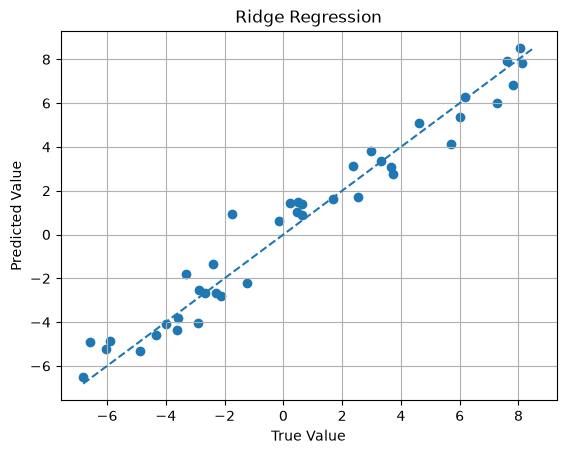

In [15]:
X_test_bias = np.column_stack(
    (np.ones(len(X_test_scaled)), X_test_scaled)
)
y_pred = X_test_bias @ beta
plt.scatter(y_test, y_pred)

min_value = min(np.min(y_test), np.min(y_pred))
max_value = max(np.max(y_test), np.max(y_pred))

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "--"
)

plt.xlabel("True Value")
plt.ylabel("Predicted Value")
plt.title("Ridge Regression")

plt.grid()

plt.show()

## 8.python新知识

1.X = pd.DataFrame({"x1": x1,"x2": x2,"x3": x3})：将三组数据合成表格

2.X.head():查看 DataFrame X 的前 5 行

3.得到数据后要划分测试集和训练集，函数：train_test_split(X, y, test_size=0.2, random_state=42)。random_state=42：固定每次运行的结果，42是随机数种子

4.X_train, X_test, y_train, y_test = train_test_split(

    X,
    
    y,

    test_size=0.2,
    
    random_state=42

)

代码分行写更容易看清参数

5.axis（维度）=0：按列操作。axis=1：按行操作

6.np.column_stack()：按列拼接。stack(堆叠)。为了给线性回归里的截距项准备位置，给特征矩阵 X 前面加上一列全是 1 的数据。np.column_stack((A, B, C))：外层括号是函数调用，里面那层是一个元组，表示要拼接的多个数组。

7.元组：把多个数据放在一起的数据类型，例如a = (1, "hello", 3.14)

8.I = np.eye(X_bias.shape[1]):创建单位矩阵。.shape[1]表示列，.shape[0]表示行。

9.np.linalg.solve(A, b)：求Ax=b中x。

10.X.T：X 的转置。@：矩阵乘法

11.fit_transform()表示：先学习规则，再按这个规则转换数据。而：transform()表示：不重新学习规则，直接用之前学到的规则转换数据。

12.第一步先看需不需要标准化

13.plt.grid()添加网格线